# Etude de l'early dropout sur un problème de régression
Le dataset California Housing contient des données relatives à des groupes de logements en Californie, issues du recensement américain de 1990. La variable à prédire est le prix médian des groupe de logements exprimé en centaine de milliers de dollar. Nous avons 8 variables explicatives qui donnent des informations sur le groupe de maisons.

Comme fonction de loss nous utilisons le MSE, comme métrique de performance d'un modèle nous utilisons le R2, l'optimizer utilisé est Adam

Etapes du travail:

1. **Calibration** de la largeur et du nombre d'epochs avec le critère du papier (delta entre dropout standard et sans dropout) pour trouver un régime de sous-apprentissage.
2. **Grille early dropout** (fractions de `EARLY_GRID`) sur 5 graines, avec intervalles de confiance à 95 %.

In [64]:
import os, glob
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from config import BATCH, P, EARLY_GRID
from models import mlp
from train import entrainer_regression

In [65]:
X, y = fetch_california_housing(return_X_y=True)      # télécharge au premier appel (Internet requis), puis cache
print(X.shape, y.shape)                                # (20640, 8) (20640,)

# 60 % train / 20 % val / 20 % test (splits fixes)
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=1)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=1)

# normalisation avec les stats du train uniquement (en numpy, avant la conversion en tenseurs)
sx = StandardScaler().fit(X_train)
X_train, X_val, X_test = sx.transform(X_train), sx.transform(X_val), sx.transform(X_test)

# cibles standardisées aussi : MSE en unités d'écart-type², R² ≈ 1 - MSE
y_mu, y_sd = y_train.mean(), y_train.std()
y_train, y_val, y_test = [(a - y_mu) / y_sd for a in (y_train, y_val, y_test)]

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
data = dict(Xtr=to_t(X_train), ytr=to_t(y_train), Xva=to_t(X_val), yva=to_t(y_val),
            Xte=to_t(X_test), yte=to_t(y_test))
print(data["Xtr"].shape, data["Xva"].shape, data["Xte"].shape)

(20640, 8) (20640,)
torch.Size([12384, 8]) torch.Size([4128, 8]) torch.Size([4128, 8])


## Paramètres propres à ce cadre

`EARLY_GRID` (dans `config.py`) donne la durée de la phase de dropout en fraction de `EPOCHS` :
0 = pas de dropout, 1 = dropout standard (tout l'entraînement), entre les deux = early dropout.

In [66]:
CADRE = "mlp_california"
OUT = "resultats"
os.makedirs(OUT, exist_ok=True)

# Calibration du nombre d'epochs et de la largeur du modèle
On entraîne le même modèle sans dropout puis avec dropout standard, et on regarde la différence de R² de validation (le delta, en points).
Le dropout standard retire de la capacité au modèle.

- Si le modèle surapprend, retirer de la capacité l'aide : delta > 0.
- Si le modèle sous-apprend, il manque déjà de capacité, et en retirer encore le pénalise : delta < 0.

In [67]:
CALIB_WIDTHS = [8, 16, 32, 64]
CALIB_EPOCHS = [10, 20, 50, 100]
CALIB_GRID = [0, 1]          # 0 = sans dropout, 1 = dropout standard
CALIB_SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

for WIDTH in CALIB_WIDTHS:
    for EPOCHS in CALIB_EPOCHS:
        for frac in CALIB_GRID:
            for seed in CALIB_SEEDS:
                fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
                if os.path.exists(fichier):
                    continue
                torch.manual_seed(seed)
                model, opt = mlp(8, 1, couche_cache=WIDTH)        # 8 features, 1 sortie
                hist = entrainer_regression(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS),
                                            p=P, batch=BATCH)
                hist.assign(cadre=CADRE, width=WIDTH, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)
                print(f"w{WIDTH} e{EPOCHS} frac {frac} seed {seed}  val R² {hist.val_r2.iloc[-1]:.4f}")

In [68]:
cal = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w*_e*_frac*_s*.csv"))
cal = cal[cal.width.isin(CALIB_WIDTHS) & cal.epochs.isin(CALIB_EPOCHS) & cal.frac.isin(CALIB_GRID) & cal.seed.isin(CALIB_SEEDS)]

# valeur finale = moyenne des 5 dernières epochs de chaque run
fin = (cal[cal.epoch >= cal.epochs - 5]
       .groupby(["width", "epochs", "frac", "seed"])[["train_loss", "val_loss", "val_r2"]].mean()
       .reset_index())

t = fin.pivot_table(index=["width", "epochs", "seed"], columns="frac", values="val_r2")
t["delta"] = (t[1] - t[0]) * 100                         # standard dropout- aucun dropout, en points de R²

# remontée relative de la loss de validation sans dropout, sur la moyenne glissante (fenêtre de 5 epochs) :
# (dernière fenêtre - meilleure fenêtre) / meilleure fenêtre
# 0 = la val loss est encore à son minimum à la fin ; plus c'est grand, plus elle a remonté (début de surapprentissage)
rem = {}
for (w, e, s), d in cal[cal.frac == 0].groupby(["width", "epochs", "seed"]):
    sm = d.sort_values("epoch").val_loss.rolling(5).mean().dropna()
    rem[(w, e, s)] = (sm.iloc[-1] - sm.min()) / sm.min()
rem = pd.Series(rem)
rem.index.names = ["width", "epochs", "seed"]

tab = t.groupby(["width", "epochs"]).agg(
    r2_sans_dropout=(0, "mean"),
    r2_avec_dropout=(1, "mean"),
    delta_moy=("delta", "mean"),
    delta_min=("delta", "min"),
    delta_max=("delta", "max"),
)
tab["remontee_val_loss"] = rem.groupby(["width", "epochs"]).mean()
tab["sous_apprentissage"] = tab.delta_max <= 0        # aucun gain R2 sur chaque seed
tab["pas_de_surapprentissage"] = tab.remontee_val_loss < 0.03      # moins de 3 % de remontée
tab = tab.round(3)

À lire : une configuration est retenue comme sous-apprentissage si toutes les graines ont un delta ≤ 0.

On observe que le modèle de largeur 8 entraîné sur 10 epochs est celui qui perd le plus de capacité avec dropout. Le modèle est clairement limité par sa capacité: plus la largeur du modèle augmente plus le r2 augmente. 

On décide de comparer l'effet de l'early dropout sur les modèles: 
- width=8, epoch=50 
- width=8, epoch=100 
- width=16, epoch=20 
- width=16, epoch=50 
- width=32, epoch=50 
- width=32, epoch=100 
- width=64, epoch=20 
- width=64, epoch=50 

Ces modèles sont tous en régime de sous-apprentissage.


## Entraînement sur différentes valeurs d'early dropout: 5%, 10%, 20%, 30%, 50%.
(un CSV par run, les runs déjà faits sont sautés)

In [69]:
EPOCHS_LIST = [20, 50, 100]
SEEDS = [0, 1, 2, 3, 4]
EARLY_GRID = [0, 0.05, 0.1, 0.2, 0.3, 0.5, 1]

for E in EPOCHS_LIST:
    print(E, "epochs :", [round(frac * E) for frac in EARLY_GRID], "epochs de dropout")

20 epochs : [0, 1, 2, 4, 6, 10, 20] epochs de dropout
50 epochs : [0, 2, 5, 10, 15, 25, 50] epochs de dropout
100 epochs : [0, 5, 10, 20, 30, 50, 100] epochs de dropout


In [70]:
WIDTH_EPOCHS = {8: [50, 100], 16: [20, 50], 32: [50, 100], 64: [20, 50]}

for WIDTH, EPOCHS_LIST in WIDTH_EPOCHS.items():
    print(f"Entraînement width={WIDTH}, epochs={EPOCHS_LIST}")
    for EPOCHS in EPOCHS_LIST:
        for frac in EARLY_GRID:
            for seed in SEEDS:
                fichier = f"{OUT}/{CADRE}_w{WIDTH}_e{EPOCHS}_frac{frac}_s{seed}.csv"
                if os.path.exists(fichier):
                    continue
                torch.manual_seed(seed)
                model, opt = mlp(8, 1, couche_cache=WIDTH)
                hist = entrainer_regression(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS),
                                            p=P, batch=BATCH)
                hist.assign(cadre=CADRE, width=WIDTH, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)
                print(f"e{EPOCHS} frac {frac:<4} seed {seed}  val R² {hist.val_r2.iloc[-1]:.4f}")

Entraînement width=8, epochs=[50, 100]
Entraînement width=16, epochs=[20, 50]
Entraînement width=32, epochs=[50, 100]
Entraînement width=64, epochs=[20, 50]


## Analyse : relit tous les CSV de ce cadre

In [71]:
# Analyse appariée par largeur : chaque run est comparé au run sans dropout de la même graine.
ANALYSIS_EPOCHS = {
    8: [50, 100],
    16: [20, 50],
    32: [50, 100],
    64: [20, 50],
}
T95 = {2: 12.71, 3: 4.30, 4: 3.18, 5: 2.78}

comp_by_width = {}
tab_by_width = {}

for width, epochs_list in ANALYSIS_EPOCHS.items():
    comp_runs = []
    for E in epochs_list:
        fichiers = glob.glob(f"{OUT}/{CADRE}_w{width}_e{E}_frac*_s*.csv")
        if not fichiers:
            raise FileNotFoundError(f"Aucun CSV trouvé pour width={width}, epochs={E}")

        d = pd.concat((pd.read_csv(fp) for fp in fichiers), ignore_index=True)
        d = d[d.seed.isin(SEEDS) & d.frac.isin(EARLY_GRID)]
        fe = (d[d.epoch >= E - 5]
              .groupby(["frac", "seed"])[["train_loss", "val_r2", "test_r2"]].mean()
              .reset_index())

        base = fe[fe.frac == 0].set_index("seed")
        if not set(SEEDS).issubset(base.index):
            raise ValueError(f"Baseline sans dropout incomplète pour width={width}, epochs={E}")
        for col in ["train_loss", "val_r2", "test_r2"]:
            fe[f"d_{col}"] = fe[col] - fe.seed.map(base[col])
        fe["epochs"] = E
        comp_runs.append(fe)

    comp = pd.concat(comp_runs, ignore_index=True)
    comp_by_width[width] = comp

    def ic95(values):
        n = len(values)
        if n not in T95:
            raise ValueError(f"Il faut entre 2 et 5 graines pour calculer l'IC à 95 % (reçu {n})")
        return T95[n] * values.std() / n ** 0.5

    stats = comp.groupby(["epochs", "frac"]).agg(
        gain_val=("d_val_r2", lambda x: 100 * x.mean()),
        ic_val=("d_val_r2", lambda x: 100 * ic95(x)),
        gain_test=("d_test_r2", lambda x: 100 * x.mean()),
        ic_test=("d_test_r2", lambda x: 100 * ic95(x)),
        d_train_loss=("d_train_loss", "mean"),
        ic_train_loss=("d_train_loss", ic95),
    )
    tab_by_width[width] = stats

La cellule suivante affiche les gains de R² en validation et en test (R2 early dropout - R2 sans dropout), ainsi que l'écart de loss d'entraînement par rapport au modèle sans dropout (train loss early dropout - train loss sans dropout). Les barres représentent les intervalles de confiance à 95 % sur les graines.

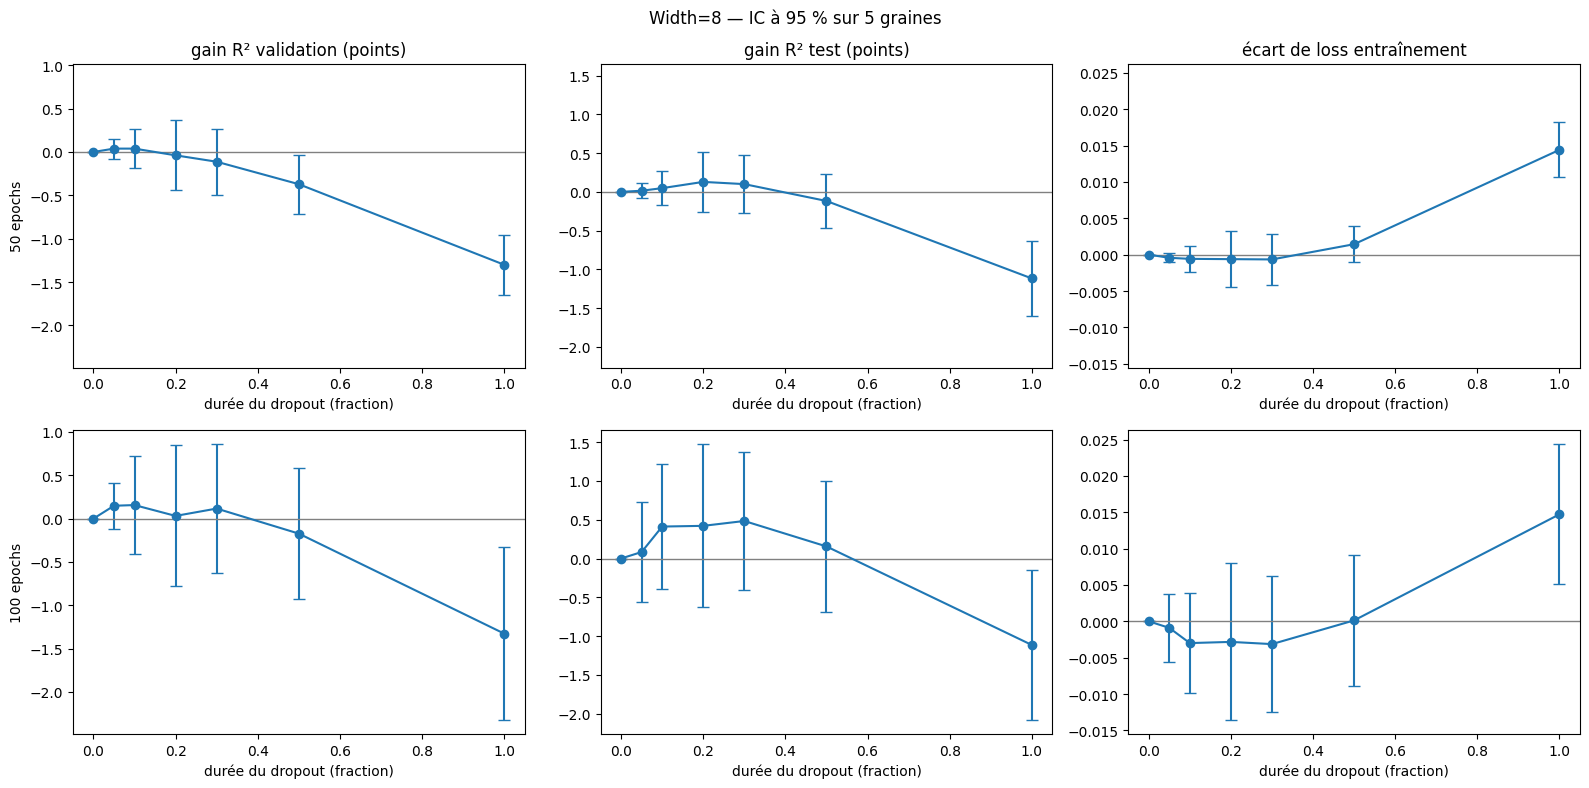

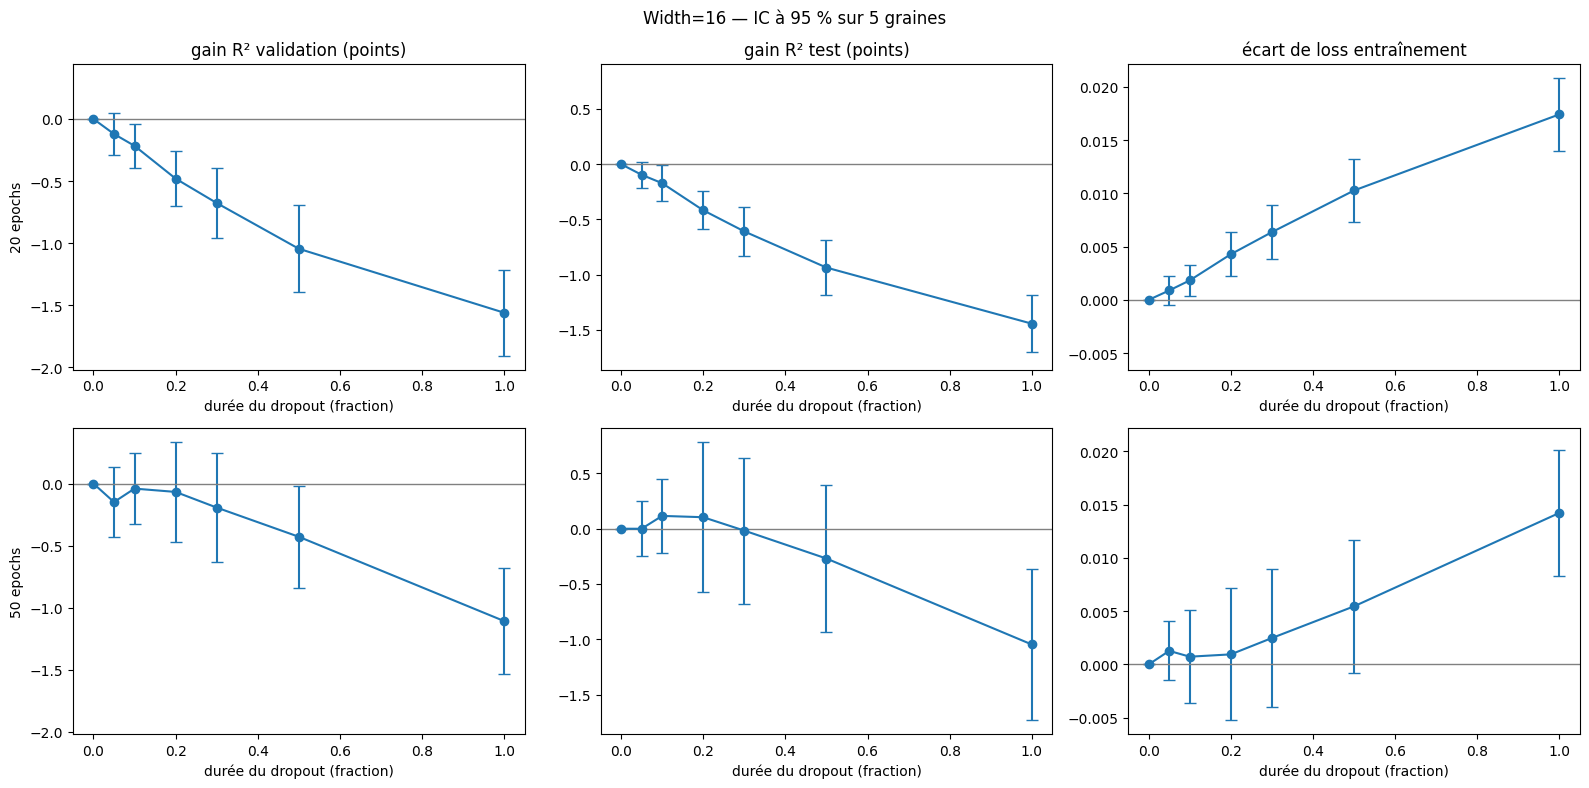

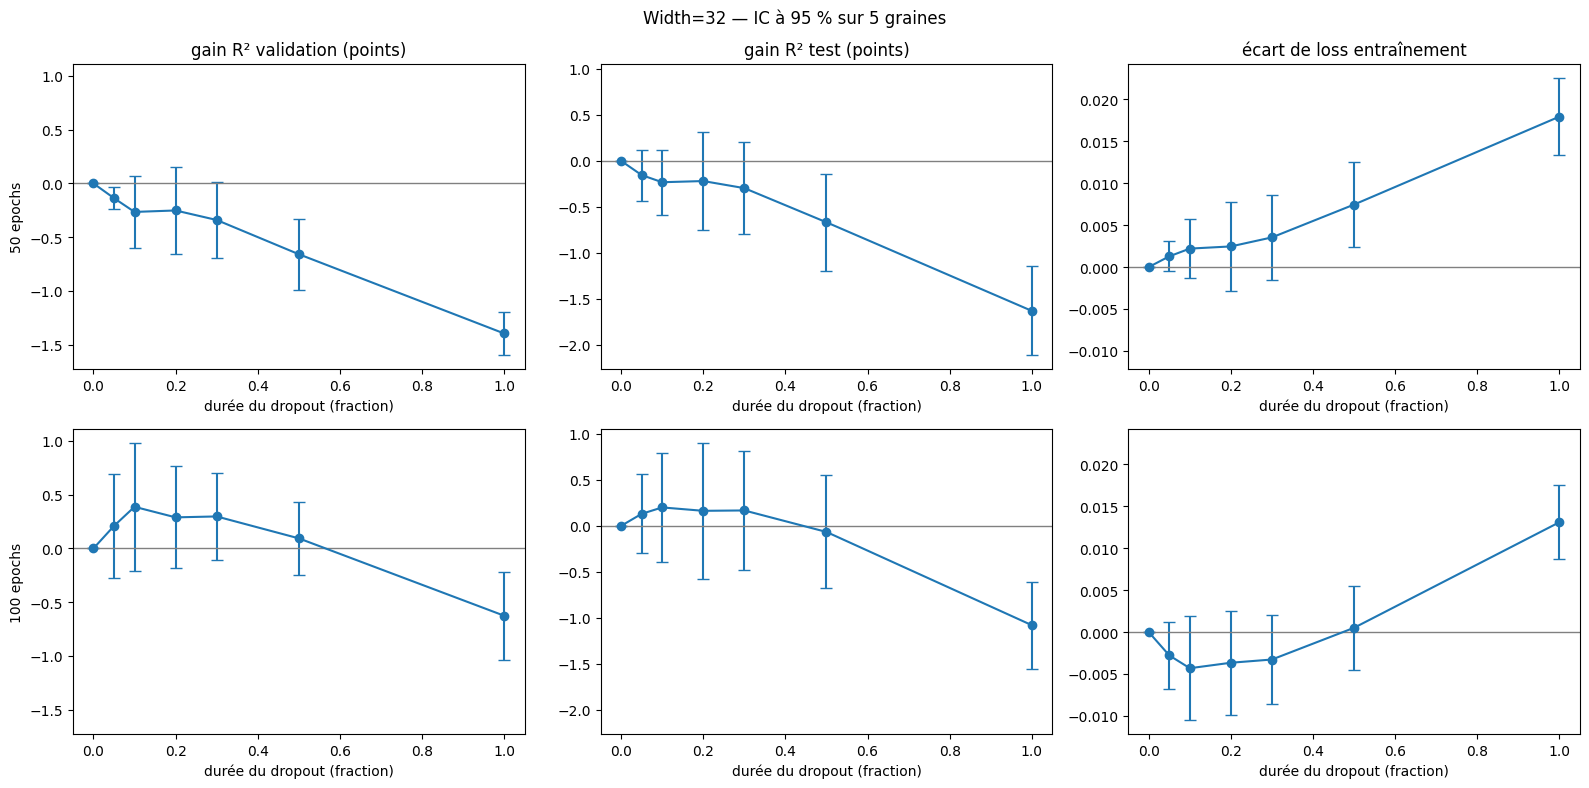

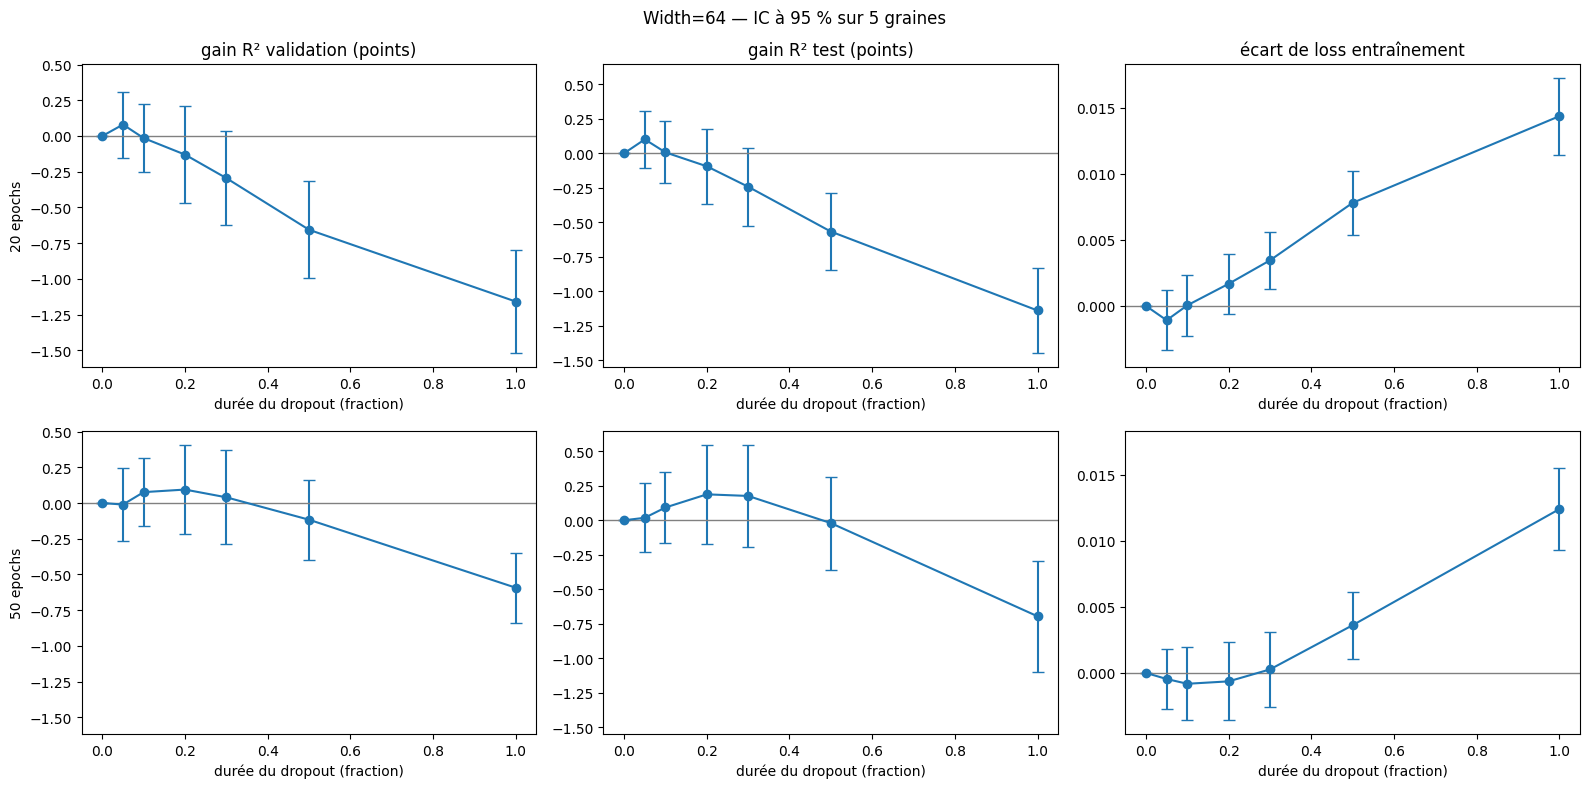

In [72]:
# Graphiques pour chaque width
for W in [8, 16, 32, 64]:
    stats = tab_by_width[W]
    fig, axes = plt.subplots(
        len(ANALYSIS_EPOCHS[W]), 3,
        figsize=(16, 4 * len(ANALYSIS_EPOCHS[W])), sharey="col", squeeze=False,
    )
    for r, E in enumerate(ANALYSIS_EPOCHS[W]):
        t = stats.xs(E, level="epochs")
        axes[r, 0].errorbar(t.index, t.gain_val, yerr=t.ic_val, marker="o", capsize=4)
        axes[r, 1].errorbar(t.index, t.gain_test, yerr=t.ic_test, marker="o", capsize=4)
        axes[r, 2].errorbar(t.index, t.d_train_loss, yerr=t.ic_train_loss, marker="o", capsize=4)
        axes[r, 0].set_ylabel(f"{E} epochs")
        for ax in axes[r]:
            ax.axhline(0, color="gray", lw=1)
            ax.set_xlabel("durée du dropout (fraction)")
    axes[0, 0].set_title("gain R² validation (points)")
    axes[0, 1].set_title("gain R² test (points)")
    axes[0, 2].set_title("écart de loss entraînement")
    fig.suptitle(f"Width={W} — IC à 95 % sur {len(SEEDS)} graines")
    fig.tight_layout()
    plt.show()

## Interprétation des graphiques

Chaque point compare une fraction d'early dropout au modèle sans dropout, graine par graine. Un gain positif de R² indique une amélioration; pour la loss d'entraînement, une différence négative est préférable. Les barres représentent les intervalles de confiance à 95 %. Lorsqu'un intervalle recouvre zéro, les résultats ne permettent pas de conclure à un effet net. Cela ne prouve pas l'absence d'effet, mais indique que l'effet observé reste incertain avec cinq graines.

### Width = 8
Les écarts de R² en validation et en test ainsi que ceux de loss varient selon le budget et la fraction de dropout. Aucune fraction ne se détache de manière suffisamment nette pour conclure à une amélioration par rapport au modèle sans dropout.

### Width = 16
Les résultats dépendent également du nombre d'epochs et ne mettent pas en évidence de fraction qui améliore de façon fiable les métriques. Les intervalles de confiance ne permettent pas de retenir un avantage statistiquement net de l'early dropout.

### Width = 32
À 100 epochs, certaines moyennes sont favorables à l'early dropout : le R² de validation et de test est plus élevé et la loss d'entraînement plus faible. Cependant, les intervalles de confiance recouvrent zéro; cette tendance n'est donc pas concluante. À 50 epochs, aucun avantage robuste ne se dégage non plus.

### Width = 64
Les différences observées varient selon la fraction et le budget d'entraînement. Les intervalles ne permettent pas d'identifier une amélioration robuste du R² ni une baisse fiable de la loss par rapport au modèle sans dropout.

## Bilan
Sur les configurations testées, aucune largeur ni fraction ne démontre à 95 % une amélioration de la loss d'entraînement ou du R² en validation ou en test. Les tendances des moyennes peuvent motiver de nouvelles expériences, mais elles ne suffisent pas à établir un bénéfice de l'early dropout.

# Étude de l'influence du batch size

On garde le même modèle width=32, 100 epochs, les mêmes fractions d'early dropout et les mêmes cinq graines. Seul le batch size varie. Cela garde constant le nombre de passages sur les données, mais le nombre de mises à jour de l'optimiseur varie : on le calcule pour chaque configuration et on l'utilise comme abscisse des graphiques. Cette comparaison mesure donc l'effet pratique du batch size à epochs fixes; elle ne sépare pas l'effet du batch size de celui du nombre total de mises à jour.

In [73]:
import math

BATCH_STUDY_WIDTH = 32
BATCH_STUDY_EPOCHS = 100
BATCH_STUDY_SIZES = [16, 32, 64, 128, 256, 512]
BATCH_STUDY_SEEDS = [0, 1, 2, 3, 4]
BATCH_STUDY_GRID = [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
n_train = len(data["Xtr"])

for bs in BATCH_STUDY_SIZES:
    steps_per_epoch = math.ceil(n_train / bs)
    for frac in BATCH_STUDY_GRID:
        for seed in BATCH_STUDY_SEEDS:
            fichier = (f"{OUT}/{CADRE}_batchsize_w{BATCH_STUDY_WIDTH}_"
                       f"e{BATCH_STUDY_EPOCHS}_bs{bs}_frac{frac}_s{seed}.csv")
            if os.path.exists(fichier):
                continue

            torch.manual_seed(seed)
            model, opt = mlp(8, 1, couche_cache=BATCH_STUDY_WIDTH)
            t_early = round(frac * BATCH_STUDY_EPOCHS)
            hist = entrainer_regression(
                model, opt, data, BATCH_STUDY_EPOCHS, t_early=t_early,
                p=P, batch=bs,
            )
            hist.assign(
                cadre=CADRE, width=BATCH_STUDY_WIDTH, epochs=BATCH_STUDY_EPOCHS,
                batch=bs, frac=frac, seed=seed,
                updates_per_epoch=steps_per_epoch,
                early_updates=t_early * steps_per_epoch,
            ).to_csv(fichier, index=False)
            print(f"batch={bs}, frac={frac}, seed={seed}: "
                  f"{t_early * steps_per_epoch} mises à jour avec dropout")

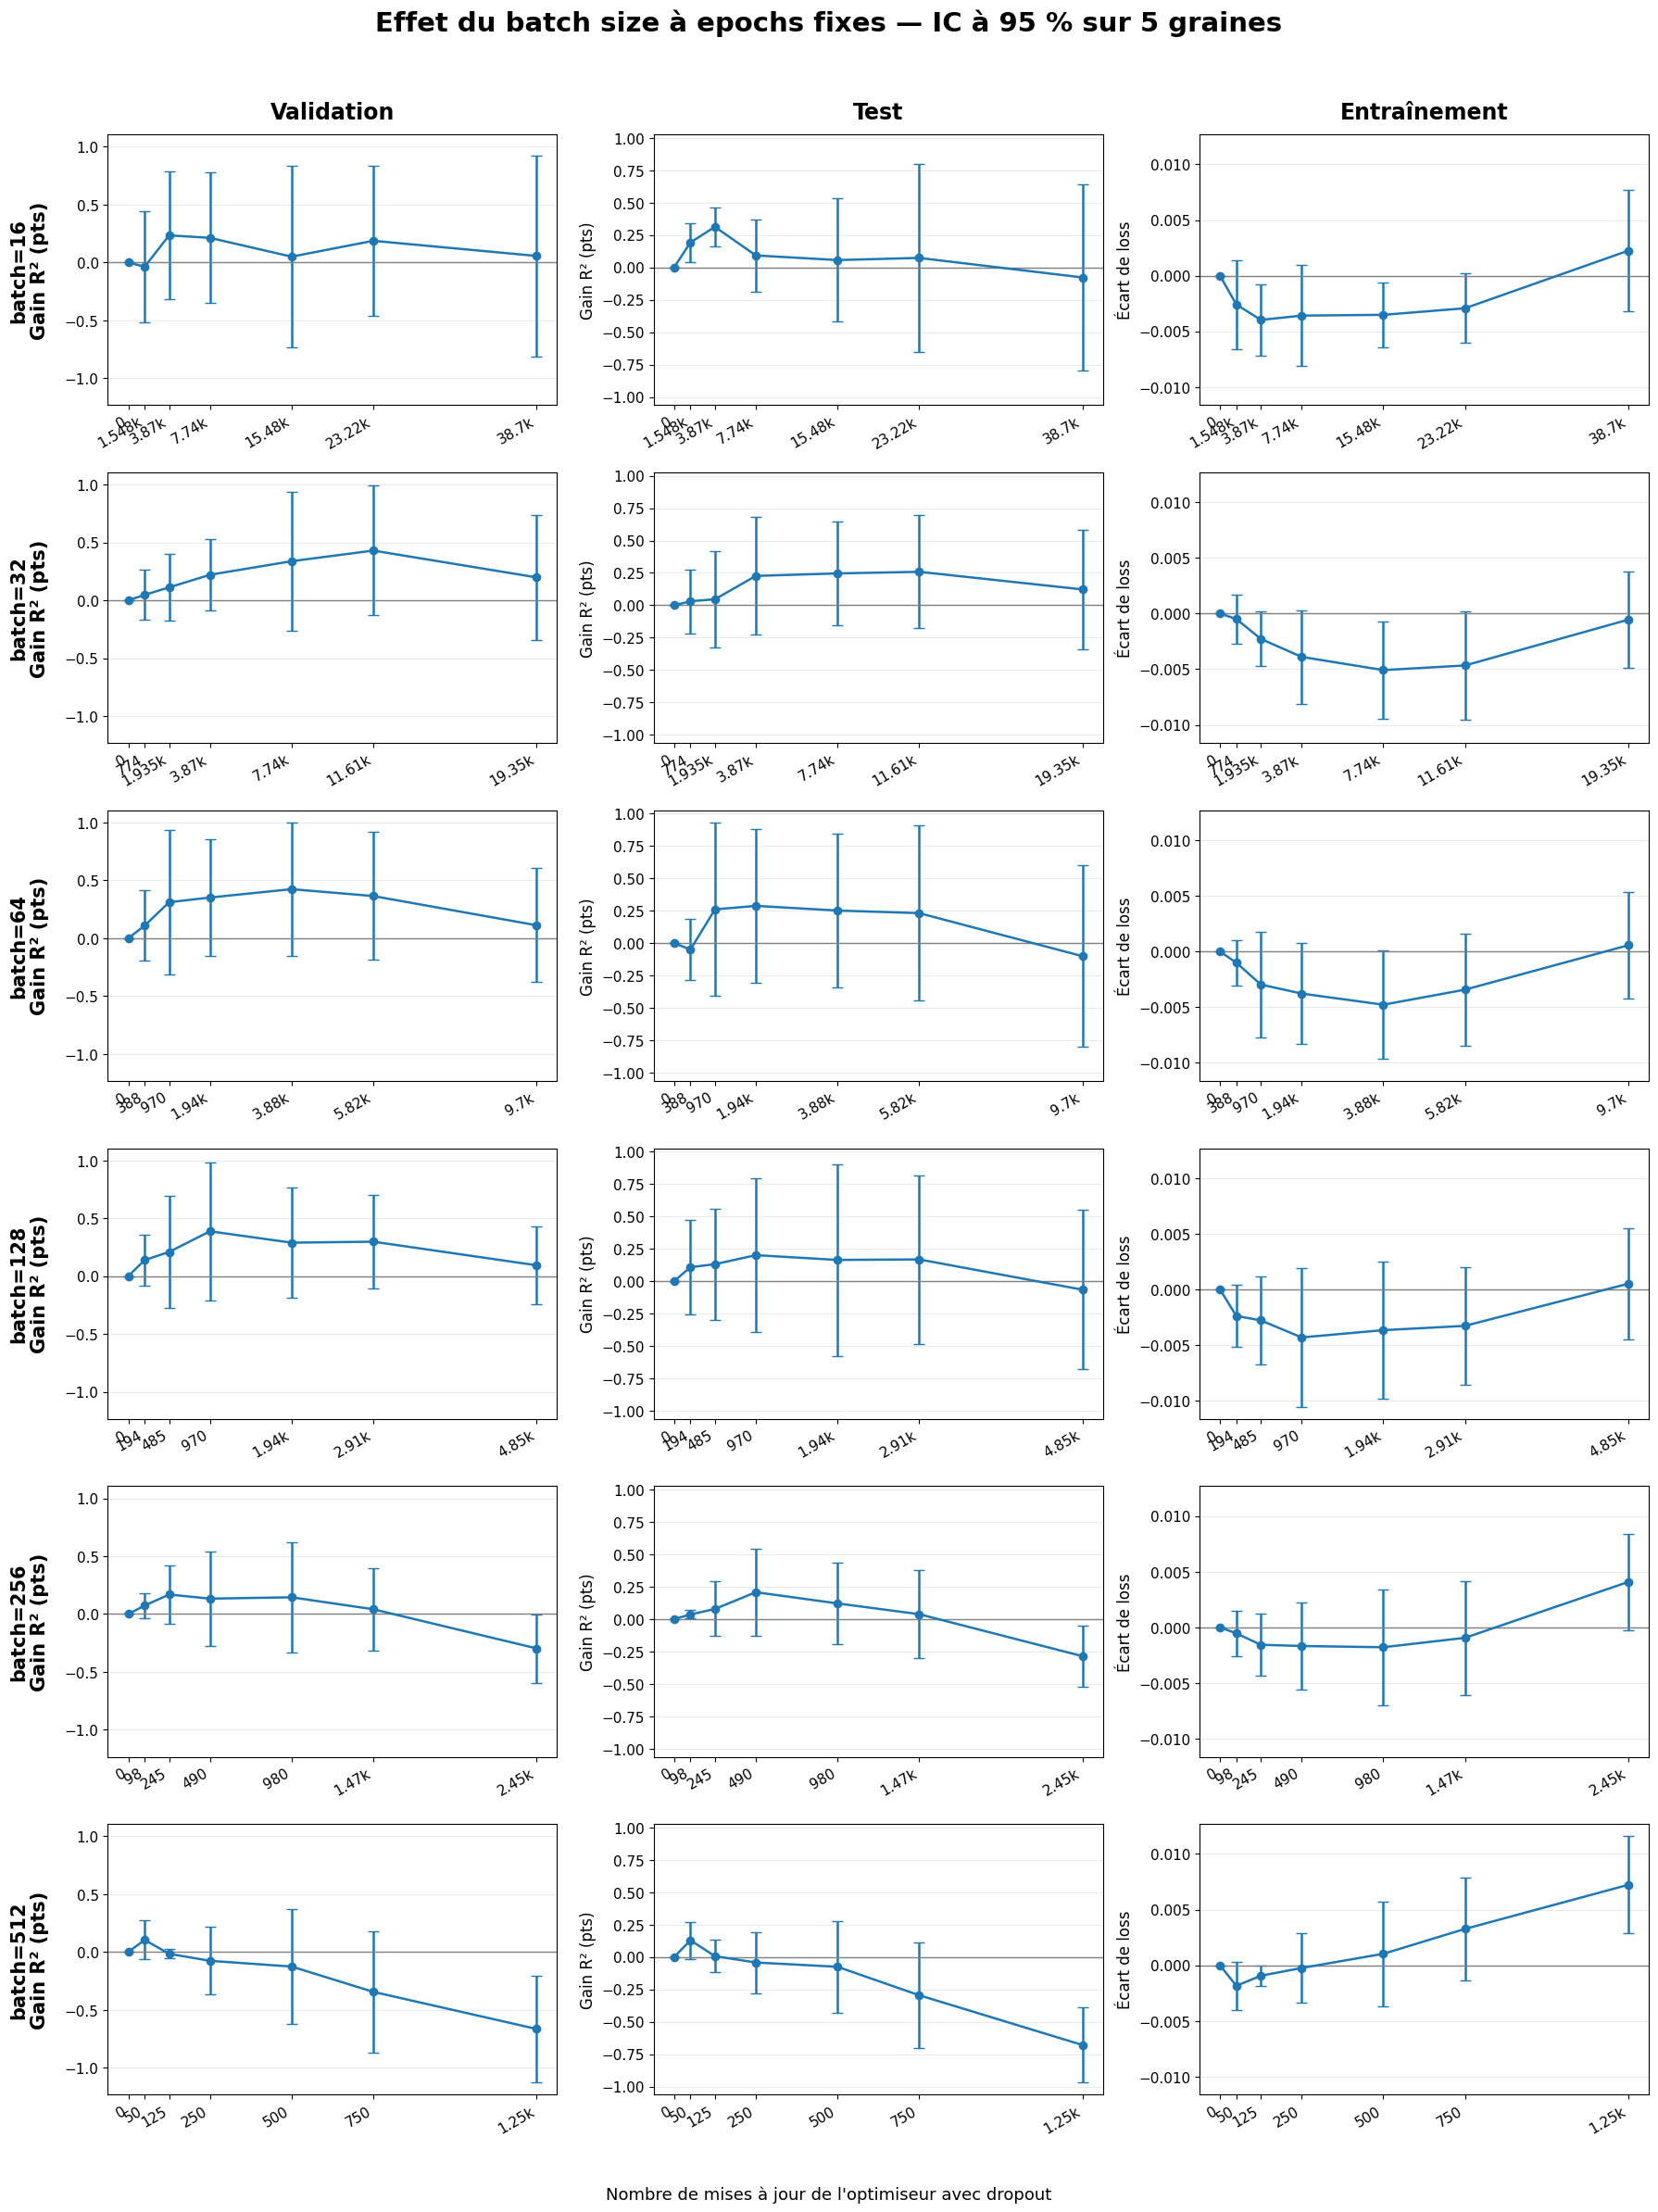

In [74]:
# Gains appariés au modèle sans dropout du même batch size et de la même graine.
batch_files = glob.glob(
    f"{OUT}/{CADRE}_batchsize_w{BATCH_STUDY_WIDTH}_e{BATCH_STUDY_EPOCHS}_bs*_frac*_s*.csv"
)
if not batch_files:
    raise FileNotFoundError("Aucun résultat batch size trouvé; exécuter la cellule d'entraînement d'abord.")

batch_runs = pd.concat((pd.read_csv(fp) for fp in batch_files), ignore_index=True)
batch_runs = batch_runs[
    batch_runs.batch.isin(BATCH_STUDY_SIZES)
    & batch_runs.frac.isin(BATCH_STUDY_GRID)
    & batch_runs.seed.isin(BATCH_STUDY_SEEDS)
]
batch_final = (
    batch_runs[batch_runs.epoch >= BATCH_STUDY_EPOCHS - 5]
    .groupby(["batch", "frac", "seed"])[["train_loss", "val_r2", "test_r2"]]
    .mean()
    .reset_index()
)

batch_baseline = batch_final[batch_final.frac == 0][
    ["batch", "seed", "train_loss", "val_r2", "test_r2"]
].rename(columns={
    "train_loss": "baseline_train_loss",
    "val_r2": "baseline_val_r2",
    "test_r2": "baseline_test_r2",
})
batch_comp = batch_final.merge(
    batch_baseline, on=["batch", "seed"], how="left", validate="many_to_one"
)
if batch_comp[["baseline_train_loss", "baseline_val_r2", "baseline_test_r2"]].isna().any().any():
    raise ValueError("Il manque une baseline sans dropout pour au moins une combinaison batch/graine.")

batch_comp["d_train_loss"] = batch_comp.train_loss - batch_comp.baseline_train_loss
batch_comp["d_val_r2"] = batch_comp.val_r2 - batch_comp.baseline_val_r2
batch_comp["d_test_r2"] = batch_comp.test_r2 - batch_comp.baseline_test_r2
batch_counts = batch_comp.groupby(["batch", "frac"]).seed.nunique()
if not batch_counts.eq(len(BATCH_STUDY_SEEDS)).all():
    raise ValueError("Chaque batch size et fraction doit avoir les cinq graines prévues.")

batch_comp["early_updates"] = [
    round(frac * BATCH_STUDY_EPOCHS) * math.ceil(n_train / bs)
    for bs, frac in zip(batch_comp.batch, batch_comp.frac)
]
T95 = {2: 12.71, 3: 4.30, 4: 3.18, 5: 2.78}

def ic95_batch(values):
    n = len(values)
    if n not in T95:
        raise ValueError(f"Nombre de graines inattendu pour l'IC à 95 % : {n}")
    return T95[n] * values.std() / n ** 0.5

batch_stats = batch_comp.groupby(["batch", "frac"]).agg(
    early_updates=("early_updates", "first"),
    gain_val=("d_val_r2", lambda x: 100 * x.mean()),
    ic_val=("d_val_r2", lambda x: 100 * ic95_batch(x)),
    gain_test=("d_test_r2", lambda x: 100 * x.mean()),
    ic_test=("d_test_r2", lambda x: 100 * ic95_batch(x)),
    d_train_loss=("d_train_loss", "mean"),
    ic_train_loss=("d_train_loss", ic95_batch),
)

fig, axes = plt.subplots(
    len(BATCH_STUDY_SIZES), 3, figsize=(18, 4 * len(BATCH_STUDY_SIZES)),
    sharex="row", sharey="col", squeeze=False,
)
for row_index, bs in enumerate(BATCH_STUDY_SIZES):
    group = batch_stats.xs(bs, level="batch").sort_values("early_updates")
    updates = group.early_updates
    axes[row_index, 0].errorbar(
        updates, group.gain_val, yerr=group.ic_val, marker="o", capsize=4, linewidth=1.8,
    )
    axes[row_index, 1].errorbar(
        updates, group.gain_test, yerr=group.ic_test, marker="o", capsize=4, linewidth=1.8,
    )
    axes[row_index, 2].errorbar(
        updates, group.d_train_loss, yerr=group.ic_train_loss, marker="o", capsize=4, linewidth=1.8,
    )
    axes[row_index, 0].set_ylabel(f"batch={bs}\nGain R² (pts)", fontsize=15, fontweight="bold", labelpad=12)
    for ax in axes[row_index]:
        ax.axhline(0, color="gray", linewidth=1)
        ax.grid(axis="y", alpha=0.25)
        ax.tick_params(axis="both", labelsize=11)
        ax.set_xticks(updates)
        ax.set_xticklabels(
            [f"{value / 1000:g}k" if value >= 1000 else str(int(value)) for value in updates],
            rotation=30, ha="right",
        )
    axes[row_index, 1].set_ylabel("Gain R² (pts)", fontsize=12)
    axes[row_index, 2].set_ylabel("Écart de loss", fontsize=12)

axes[0, 0].set_title("Validation", fontsize=17, fontweight="bold", pad=12)
axes[0, 1].set_title("Test", fontsize=17, fontweight="bold", pad=12)
axes[0, 2].set_title("Entraînement", fontsize=17, fontweight="bold", pad=12)
fig.suptitle("Effet du batch size à epochs fixes — IC à 95 % sur 5 graines",
             fontsize=21, fontweight="bold", y=0.997)
fig.supxlabel("Nombre de mises à jour de l'optimiseur avec dropout", fontsize=13)
fig.tight_layout(rect=(0, 0.02, 1, 0.98), h_pad=1.5)
plt.show()

## Interprétation de l'étude batch size

Chaque point compare l'early dropout à la configuration sans dropout, pour le même batch size et la même graine. Les métriques sont moyennées sur les cinq dernières epochs; les barres représentent des IC à 95 % calculés sur cinq graines. Un gain de R² positif est favorable; une différence de loss d'entraînement négative signifie une loss plus faible.

- **Early dropout court (2 à 30 % des epochs).** Les gains moyens de R² sont généralement faibles. La plupart des IC à 95 % recouvrent zéro : les résultats ne montrent donc pas d'amélioration robuste en validation ou en test pour la majorité des batch sizes. À batch=16, les durées 2 % et 5 % donnent un petit gain de R² test (environ +0,19 et +0,31 point), mais le gain en validation reste incertain.
- **Early dropout long (50 % des epochs).** L'effet devient défavorable pour les grands batch sizes : le R² validation/test baisse d'environ 0,30 point à batch=256 et de 0,67/0,68 point à batch=512, avec des IC qui n'incluent pas zéro. Pour les batch sizes 16 à 128, les effets à 50 % sont moins nets et restent compatibles avec l'absence d'effet.
- **Loss d'entraînement.** Elle diminue pour certaines configurations courtes, mais cela ne garantit pas une meilleure généralisation. À batch=512, elle augmente déjà clairement à 50 % d'early dropout, en même temps que les R² validation et test diminuent.

**Conclusion :** dans cette expérience, aucun batch size ne bénéficie systématiquement de l'early dropout. Les courtes durées sont souvent neutres; une durée trop longue peut nuire, surtout avec batch=256 ou 512. Les intervalles reposent sur seulement cinq graines, donc les petits écarts doivent être interprétés avec prudence.

**Limite de comparaison :** le nombre d'epochs est fixé à 100, mais le nombre de mises à jour par epoch varie avec le batch size. La taille du batch et le nombre total de mises à jour changent donc ensemble; cette expérience ne permet pas d'attribuer toute différence au seul batch size.

Quand le batch size est plus petit, on fait plus d'itérations mais la variation de la direction des gradients est plus élevé car moins d'observations par batch. Tandis que quand le batch size est plus grand les gradients ont tendances à avoir une direction plus homogène. Dans le papier, ils nous disent que l'early dropout diminue la variance des directions des gradients au début de l'entraînement. Cela pourrait expliquer pourquoi on a tendance à avoir de meilleurs résultats sur les petits batch size.

Pour tester cette hypothèse, une solution serait d'aller observer en détail la direction des gradients au débuts des entrainements.